In [1]:
# =============================================================================
# Pattern Recognition and Machine Learning (EE602L)
# Lab 5 : Decision Trees for Classification and Regression
# Author : IS24BM008
# =============================================================================
#
# STRUCTURE OF THIS NOTEBOOK
#   Cells  1 - 13 : Question 1  (Decision Tree Classification, Iris)
#   Cells 14 - 22 : Question 2  (Decision Tree Regression, Diabetes)
#
# EVERY experimental number quoted in the accompanying PDF report is produced by
# this notebook and dumped to results.json at the end, so report and code can
# never disagree.
#
# REPRODUCIBILITY
#   random_state=42 is passed to every split and every estimator. This matters
#   more than it looks: CART as implemented in scikit-learn is *randomised* even
#   when splitter='best', because at each node the features are permuted before
#   being scanned and ties in impurity decrease are therefore broken randomly.
#   Two runs of the "same" unrestricted tree can differ in structure without a
#   fixed seed.
# =============================================================================

import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.tree import (DecisionTreeClassifier, DecisionTreeRegressor,
                          plot_tree, export_text)
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             mean_squared_error, mean_absolute_error)

SEED = 42
FIGDIR = "figs"
import os
os.makedirs(FIGDIR, exist_ok=True)

np.random.seed(SEED)
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150,
                     "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.3})

RESULTS = {}          # everything the report needs ends up in here

print("numpy", np.__version__)
import sklearn
print("scikit-learn", sklearn.__version__)

numpy 2.4.1
scikit-learn 1.8.0


In [2]:
# =============================================================================
# Q1 (a) - PART 1 : LOAD THE IRIS DATA
# =============================================================================
# 150 samples, 4 real-valued features (sepal/petal length and width in cm),
# 3 perfectly balanced classes (50 each). The class balance is the reason
# plain accuracy is an acceptable headline metric here; on an imbalanced
# problem it would not be, which is exactly why part (c) also asks for
# macro-averaged precision / recall / F1.
# =============================================================================

iris = load_iris()
X_iris, y_iris = iris.data, iris.target
FEATS_IRIS = list(iris.feature_names)
CLASSES_IRIS = [str(c) for c in iris.target_names]

print("Feature matrix :", X_iris.shape)
print("Target vector  :", y_iris.shape)
print("Features       :", FEATS_IRIS)
print("Classes        :", CLASSES_IRIS)
print("Class counts   :", np.bincount(y_iris))

# NOTE ON SCALING: no standardisation is applied anywhere in this lab, and that
# is deliberate rather than an oversight. A decision tree splits on a single
# feature at a time using a threshold test x_j <= t. Any strictly monotone
# transform of x_j maps the candidate thresholds one-to-one and leaves the
# induced partition - and therefore the impurity of every candidate split -
# unchanged. Trees are invariant to feature scaling, unlike logistic regression
# or SVMs from the previous labs.

df_head = pd.DataFrame(X_iris, columns=FEATS_IRIS).assign(
    target=y_iris, species=[CLASSES_IRIS[i] for i in y_iris]).head()
print()
print(df_head)

Feature matrix : (150, 4)
Target vector  : (150,)
Features       : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes        : ['setosa', 'versicolor', 'virginica']
Class counts   : [50 50 50]

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  target species
0                5.1               3.5                1.4               0.2       0  setosa
1                4.9               3.0                1.4               0.2       0  setosa
2                4.7               3.2                1.3               0.2       0  setosa
3                4.6               3.1                1.5               0.2       0  setosa
4                5.0               3.6                1.4               0.2       0  setosa


In [3]:
# =============================================================================
# Q1 (a) - PART 2 : 70 : 15 : 15 STRATIFIED SPLIT WITH SEED 42
# =============================================================================
# Done in two stages because train_test_split only produces two parts:
#   stage 1 : 150 -> 105 train (70%) + 45 temp (30%)
#   stage 2 :  45 temp -> 22/23 val + 23/22 test (50% of 30% = 15% each)
# stratify= is passed at BOTH stages. Stratifying only the first stage would
# leave the val/test proportions to chance, and with only ~22 samples per part
# that chance is not small.
#
# WHY STRATIFY AT ALL: with 15% splits the validation set has ~22 points. An
# unstratified draw could easily give 5 of one class and 11 of another, and the
# model-selection decisions in part (b) would then be driven by sampling noise
# in the validation split rather than by max_depth.
# =============================================================================

X_tr_i, X_tmp_i, y_tr_i, y_tmp_i = train_test_split(
    X_iris, y_iris, test_size=0.30, random_state=SEED, stratify=y_iris)

X_val_i, X_te_i, y_val_i, y_te_i = train_test_split(
    X_tmp_i, y_tmp_i, test_size=0.50, random_state=SEED, stratify=y_tmp_i)

split_tbl_i = pd.DataFrame({
    "n": [len(y_tr_i), len(y_val_i), len(y_te_i)],
    "fraction": [len(y_tr_i) / 150, len(y_val_i) / 150, len(y_te_i) / 150],
    "setosa": [int((y == 0).sum()) for y in (y_tr_i, y_val_i, y_te_i)],
    "versicolor": [int((y == 1).sum()) for y in (y_tr_i, y_val_i, y_te_i)],
    "virginica": [int((y == 2).sum()) for y in (y_tr_i, y_val_i, y_te_i)],
}, index=["train", "val", "test"])
print(split_tbl_i)

RESULTS["q1_split"] = split_tbl_i.to_dict(orient="index")

# A 22-point validation set means validation accuracy moves in steps of
# 1/22 = 4.55 percentage points. Differences smaller than one step are not
# real; this granularity is used explicitly as a tie-breaking argument later.
RESULTS["q1_val_granularity"] = 1.0 / len(y_val_i)
print("\nValidation accuracy resolution : 1/%d = %.4f" %
      (len(y_val_i), 1 / len(y_val_i)))

         n  fraction  setosa  versicolor  virginica
train  105  0.700000      35          35         35
val     22  0.146667       8           7          7
test    23  0.153333       7           8          8

Validation accuracy resolution : 1/22 = 0.0455


In [4]:
# =============================================================================
# Q1 - IMPURITY MEASURES : WHAT ENTROPY AND GINI ACTUALLY COMPUTE
# =============================================================================
# For a node with class proportions p_1..p_K:
#
#   Gini(p)    = 1 - sum_k p_k^2          = sum_k p_k (1 - p_k)
#   Entropy(p) = - sum_k p_k log2(p_k)
#
# INTERPRETATION
#   Gini is the probability that two independent draws from the node's label
#   distribution disagree - equivalently the expected 0/1 error of a randomised
#   classifier that predicts class k with probability p_k.
#   Entropy is the expected number of bits needed to encode a label drawn from
#   the node. Information gain is then the reduction in that code length.
#
# A split is scored by the WEIGHTED impurity decrease
#   dI = I(parent) - (n_L/n) I(left) - (n_R/n) I(right)
# and CART picks the (feature, threshold) pair maximising dI. Both measures are
# strictly concave and are zero exactly at a pure node, which is what makes dI
# non-negative for any split.
#
# The cell below evaluates both on the actual training root and on a few
# reference distributions, so the claim "they are close but entropy punishes
# impure nodes harder" is backed by numbers rather than asserted.
# =============================================================================

def gini(p):
    p = np.asarray(p, dtype=float)
    return 1.0 - np.sum(p ** 2)

def entropy(p):
    p = np.asarray(p, dtype=float)
    p = p[p > 0]                      # 0 log 0 := 0
    return float(-np.sum(p * np.log2(p)) + 0.0)   # +0.0 kills the -0.0 display artefact

p_root = np.bincount(y_tr_i, minlength=3) / len(y_tr_i)
print("Training-root class proportions :", np.round(p_root, 4))
print("Gini(root)    = %.4f   (max for 3 classes = %.4f)" % (gini(p_root), 1 - 1 / 3))
print("Entropy(root) = %.4f   (max for 3 classes = %.4f)" % (entropy(p_root), np.log2(3)))

ref = {"pure [1,0]": [1, 0], "[0.9,0.1]": [.9, .1], "[0.7,0.3]": [.7, .3],
       "[0.5,0.5]": [.5, .5], "3-class uniform": [1 / 3, 1 / 3, 1 / 3]}
imp_tbl = pd.DataFrame({"Gini": [gini(v) for v in ref.values()],
                        "Entropy": [entropy(v) for v in ref.values()]},
                       index=list(ref.keys())).round(4)
print()
print(imp_tbl)
RESULTS["q1_impurity_reference"] = imp_tbl.to_dict(orient="index")
RESULTS["q1_root_impurity"] = {"gini": gini(p_root), "entropy": entropy(p_root)}

# Reading the table: entropy is larger than Gini for every impure distribution
# and grows faster as the node approaches uniform. Because entropy has a steeper
# slope near the pure end, it slightly favours splits that isolate a small very
# pure region, while Gini slightly favours splits that produce the largest
# majority class. In practice, as the sweep below confirms, the two almost
# always induce the same tree.

Training-root class proportions : [0.3333 0.3333 0.3333]
Gini(root)    = 0.6667   (max for 3 classes = 0.6667)
Entropy(root) = 1.5850   (max for 3 classes = 1.5850)

                   Gini  Entropy
pure [1,0]       0.0000   0.0000
[0.9,0.1]        0.1800   0.4690
[0.7,0.3]        0.4200   0.8813
[0.5,0.5]        0.5000   1.0000
3-class uniform  0.6667   1.5850


In [5]:
# =============================================================================
# Q1 (a) - PART 3 : max_depth SWEEP FOR BOTH CRITERIA
# =============================================================================
# Seven depths, including None (= unrestricted, grow until every leaf is pure
# or has one sample), for each of entropy and Gini -> 14 fitted trees.
# For each we record train accuracy, validation accuracy, the realised depth
# (which can be smaller than max_depth once purity is reached) and the leaf
# count (the complexity measure that actually matters).
# =============================================================================

DEPTHS = [1, 2, 3, 4, 5, 6, None]
CRITERIA = ["entropy", "gini"]

rows = []
clf_store = {}                       # (criterion, depth) -> fitted model
for crit in CRITERIA:
    for d in DEPTHS:
        clf = DecisionTreeClassifier(criterion=crit, max_depth=d,
                                     random_state=SEED)
        clf.fit(X_tr_i, y_tr_i)
        clf_store[(crit, d)] = clf
        rows.append({
            "criterion": crit,
            "max_depth": "None" if d is None else d,
            "train_acc": accuracy_score(y_tr_i, clf.predict(X_tr_i)),
            "val_acc": accuracy_score(y_val_i, clf.predict(X_val_i)),
            "realised_depth": clf.get_depth(),
            "n_leaves": clf.get_n_leaves(),
        })

depth_df = pd.DataFrame(rows)
print(depth_df.to_string(index=False,
                         formatters={"train_acc": "{:.4f}".format,
                                     "val_acc": "{:.4f}".format}))

RESULTS["q1_depth_sweep"] = depth_df.to_dict(orient="records")

# The train-accuracy column is the diagnostic to read first: it is monotone
# non-decreasing in max_depth by construction, because a deeper tree can always
# reproduce a shallower one and then split further. Validation accuracy is under
# no such obligation, and the gap between the two curves is exactly the
# quantity "overfitting" refers to.

criterion max_depth train_acc val_acc  realised_depth  n_leaves
  entropy         1    0.6667  0.6818               1         2
  entropy         2    0.9714  0.9091               2         3
  entropy         3    0.9810  0.9545               3         5
  entropy         4    0.9905  0.9091               4         6
  entropy         5    0.9905  0.9091               5         7
  entropy         6    1.0000  0.9091               6         8
  entropy      None    1.0000  0.9091               6         8
     gini         1    0.6667  0.6818               1         2
     gini         2    0.9714  0.9091               2         3
     gini         3    0.9810  0.9545               3         5
     gini         4    0.9905  0.9091               4         7
     gini         5    1.0000  0.9545               5         8
     gini         6    1.0000  0.9545               5         8
     gini      None    1.0000  0.9545               5         8


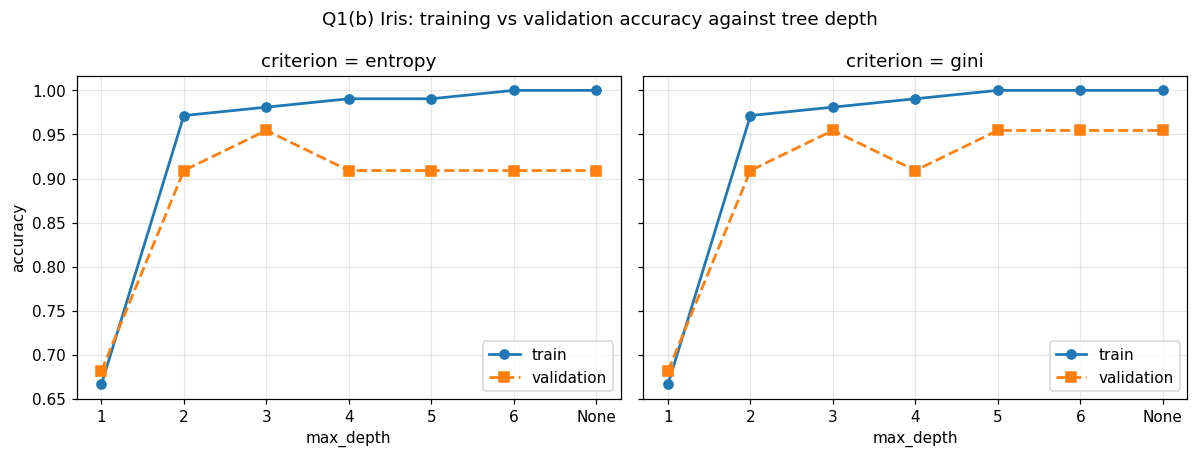

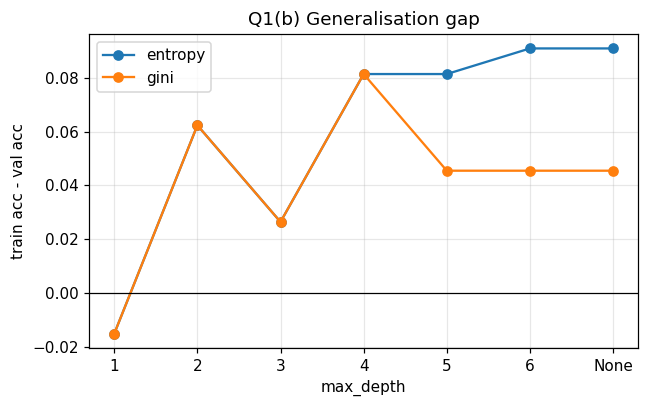

In [6]:
# =============================================================================
# Q1 (b) - PART 1 : ACCURACY vs max_depth PLOT
# =============================================================================
# The unrestricted tree is plotted at x = realised depth + 1 so that it sits to
# the right of every constrained model; its x tick is relabelled "None".
# =============================================================================

x_vals = [d if d is not None else max(DEPTHS[:-1]) + 1 for d in DEPTHS]
x_ticklabels = [str(d) if d is not None else "None" for d in DEPTHS]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, crit in zip(axes, CRITERIA):
    sub = depth_df[depth_df.criterion == crit]
    ax.plot(x_vals, sub.train_acc, "o-", label="train", lw=1.8)
    ax.plot(x_vals, sub.val_acc, "s--", label="validation", lw=1.8)
    ax.set_xticks(x_vals)
    ax.set_xticklabels(x_ticklabels)
    ax.set_xlabel("max_depth")
    ax.set_title("criterion = %s" % crit)
    ax.legend(loc="lower right")
axes[0].set_ylabel("accuracy")
fig.suptitle("Q1(b) Iris: training vs validation accuracy against tree depth")
fig.tight_layout()
fig.savefig(f"{FIGDIR}/q1_depth_curves.png", bbox_inches="tight")
plt.show()

# Companion plot: the train-validation gap, which is the cleanest single view
# of where the extra depth stops buying generalisation and starts buying
# memorisation.
fig, ax = plt.subplots(figsize=(6, 3.8))
for crit in CRITERIA:
    sub = depth_df[depth_df.criterion == crit]
    ax.plot(x_vals, sub.train_acc.values - sub.val_acc.values, "o-", label=crit)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(x_vals); ax.set_xticklabels(x_ticklabels)
ax.set_xlabel("max_depth"); ax.set_ylabel("train acc - val acc")
ax.set_title("Q1(b) Generalisation gap")
ax.legend()
fig.tight_layout()
fig.savefig(f"{FIGDIR}/q1_gap.png", bbox_inches="tight")
plt.show()

In [7]:
# =============================================================================
# Q1 (b) - PART 2 : WHERE DOES OVERFITTING START, AND WHICH MODEL DO WE KEEP
# =============================================================================
# SELECTION RULE (fixed before looking at the numbers, so it cannot be tuned
# after the fact):
#   1. best validation accuracy;
#   2. ties broken towards the SMALLER max_depth (Occam / structural risk: among
#      models with indistinguishable validation performance, prefer the one with
#      the smaller hypothesis class);
#   3. the criterion is chosen by its best validation accuracy, and if those tie
#      by the MEAN validation accuracy over the whole depth grid, which is a
#      less noisy statistic than a single 22-point evaluation.
# The test set is not consulted anywhere in this cell.
# =============================================================================

summary_crit = depth_df.groupby("criterion").agg(
    best_val=("val_acc", "max"), mean_val=("val_acc", "mean")).round(4)
print(summary_crit)

best_val_overall = depth_df.val_acc.max()
cands = depth_df[np.isclose(depth_df.val_acc, best_val_overall)]
print("\nConfigurations attaining the best validation accuracy (%.4f):" % best_val_overall)
print(cands.to_string(index=False))

best_crit = summary_crit.best_val.idxmax()
if np.isclose(summary_crit.best_val.max(), summary_crit.best_val.min()):
    best_crit = summary_crit.mean_val.idxmax()
    crit_reason = "tie on best validation accuracy, broken by mean validation accuracy over the depth grid"
else:
    crit_reason = "strictly higher best validation accuracy"

sub_best = depth_df[(depth_df.criterion == best_crit) &
                    np.isclose(depth_df.val_acc, depth_df[depth_df.criterion == best_crit].val_acc.max())]
# smallest depth among the tied ones ("None" sorts last by construction)
depth_order = {("None" if d is None else d): i for i, d in enumerate(DEPTHS)}
best_depth_label = min(sub_best.max_depth, key=lambda d: depth_order[d])
best_depth = None if best_depth_label == "None" else int(best_depth_label)

print("\nSelected criterion : %s   (%s)" % (best_crit, crit_reason))
print("Selected max_depth : %s" % best_depth_label)

# Onset of overfitting: the first depth beyond which training accuracy keeps
# rising while validation accuracy does not improve.
sub_c = depth_df[depth_df.criterion == best_crit].reset_index(drop=True)
onset = None
for k in range(len(sub_c) - 1):
    later = sub_c.iloc[k + 1:]
    if (later.train_acc > sub_c.train_acc[k] + 1e-12).any() and \
       (later.val_acc <= sub_c.val_acc[k] + 1e-12).all():
        onset = sub_c.max_depth[k]
        break
print("Overfitting sets in beyond max_depth = %s (for criterion %s)" % (onset, best_crit))

pre_pruned = clf_store[(best_crit, best_depth)]
print("Pre-pruned model : depth=%d, leaves=%d" %
      (pre_pruned.get_depth(), pre_pruned.get_n_leaves()))

RESULTS["q1_criterion_summary"] = summary_crit.to_dict(orient="index")
RESULTS["q1_selection"] = {
    "criterion": best_crit, "criterion_reason": crit_reason,
    "max_depth": best_depth_label, "overfit_onset_depth": str(onset),
    "best_val_acc": float(sub_best.val_acc.iloc[0]),
    "pre_depth": int(pre_pruned.get_depth()),
    "pre_leaves": int(pre_pruned.get_n_leaves()),
    "n_tied_configs": int(len(cands)),
}

           best_val  mean_val
criterion                    
entropy      0.9545    0.8831
gini         0.9545    0.9026

Configurations attaining the best validation accuracy (0.9545):
criterion max_depth  train_acc  val_acc  realised_depth  n_leaves
  entropy         3   0.980952 0.954545               3         5
     gini         3   0.980952 0.954545               3         5
     gini         5   1.000000 0.954545               5         8
     gini         6   1.000000 0.954545               5         8
     gini      None   1.000000 0.954545               5         8

Selected criterion : gini   (tie on best validation accuracy, broken by mean validation accuracy over the depth grid)
Selected max_depth : 3
Overfitting sets in beyond max_depth = 3 (for criterion gini)
Pre-pruned model : depth=3, leaves=5


In [8]:
# =============================================================================
# Q1 (b) - PART 3 : POST-PRUNING WITH MINIMAL COST-COMPLEXITY (ccp_alpha)
# =============================================================================
# THEORY. Grow the tree fully, then for a penalty alpha >= 0 score any subtree T
# of the full tree T0 by
#       R_alpha(T) = R(T) + alpha * |leaves(T)|
# where R(T) is the training misclassification cost (weighted impurity in
# sklearn's implementation). Breiman's result is that the minimisers of R_alpha
# over subtrees form a finite NESTED sequence T0 > T1 > ... > {root} as alpha
# increases, and that each Tk is obtained from T(k-1) by collapsing the internal
# node with the smallest "effective alpha" - the alpha at which keeping that
# subtree stops paying for its own leaves. So the search is over a handful of
# nested trees, not over all 2^(#nodes) subtrees.
#
# cost_complexity_pruning_path returns exactly those breakpoints for the fully
# grown tree, which is why the alphas below are read off the data rather than
# guessed on a log grid.
#
# POST- vs PRE-PRUNING. max_depth decides to stop BEFORE seeing what a subtree
# would have achieved, so it is vulnerable to the XOR-type situation where a
# useless-looking split enables two very good children. ccp_alpha decides AFTER
# growing, with the children's actual training cost in hand, so it can keep a
# deep branch in one region of the space and collapse a shallow one elsewhere -
# it prunes non-uniformly, which max_depth cannot do.
# =============================================================================

full_tree = DecisionTreeClassifier(criterion=best_crit, random_state=SEED)
full_tree.fit(X_tr_i, y_tr_i)
path = full_tree.cost_complexity_pruning_path(X_tr_i, y_tr_i)
alphas, impurities = path.ccp_alphas, path.impurities

print("Fully grown tree : depth=%d, leaves=%d, train acc=%.4f" %
      (full_tree.get_depth(), full_tree.get_n_leaves(),
       accuracy_score(y_tr_i, full_tree.predict(X_tr_i))))
print("\nPruning path (%d breakpoints):" % len(alphas))
print(pd.DataFrame({"ccp_alpha": alphas, "total_leaf_impurity": impurities}).round(5).to_string(index=False))

# Every breakpoint on the path is used, which is well above the required four.
# The final alpha collapses the tree to its root and is kept in the sweep on
# purpose: it is the reference point showing what over-pruning costs.
rows = []
pruned_store = {}
for a in alphas:
    t = DecisionTreeClassifier(criterion=best_crit, random_state=SEED, ccp_alpha=a)
    t.fit(X_tr_i, y_tr_i)
    pruned_store[float(a)] = t
    rows.append({"ccp_alpha": float(a),
                 "train_acc": accuracy_score(y_tr_i, t.predict(X_tr_i)),
                 "val_acc": accuracy_score(y_val_i, t.predict(X_val_i)),
                 "depth": t.get_depth(), "n_leaves": t.get_n_leaves()})
ccp_df = pd.DataFrame(rows)
print()
print(ccp_df.to_string(index=False, formatters={"ccp_alpha": "{:.5f}".format,
                                                "train_acc": "{:.4f}".format,
                                                "val_acc": "{:.4f}".format}))
RESULTS["q1_ccp_sweep"] = ccp_df.to_dict(orient="records")
RESULTS["q1_full_tree"] = {"depth": int(full_tree.get_depth()),
                           "leaves": int(full_tree.get_n_leaves()),
                           "train_acc": float(accuracy_score(y_tr_i, full_tree.predict(X_tr_i))),
                           "val_acc": float(accuracy_score(y_val_i, full_tree.predict(X_val_i))),
                           "n_alphas": int(len(alphas))}

Fully grown tree : depth=5, leaves=8, train acc=1.0000

Pruning path (5 breakpoints):
 ccp_alpha  total_leaf_impurity
   0.00000              0.00000
   0.00899              0.03598
   0.01849              0.05447
   0.27887              0.33333
   0.33333              0.66667

ccp_alpha train_acc val_acc  depth  n_leaves
  0.00000    1.0000  0.9545      5         8
  0.00899    0.9810  0.9545      3         4
  0.01849    0.9714  0.9091      2         3
  0.27887    0.6667  0.6818      1         2
  0.33333    0.3333  0.3636      0         1


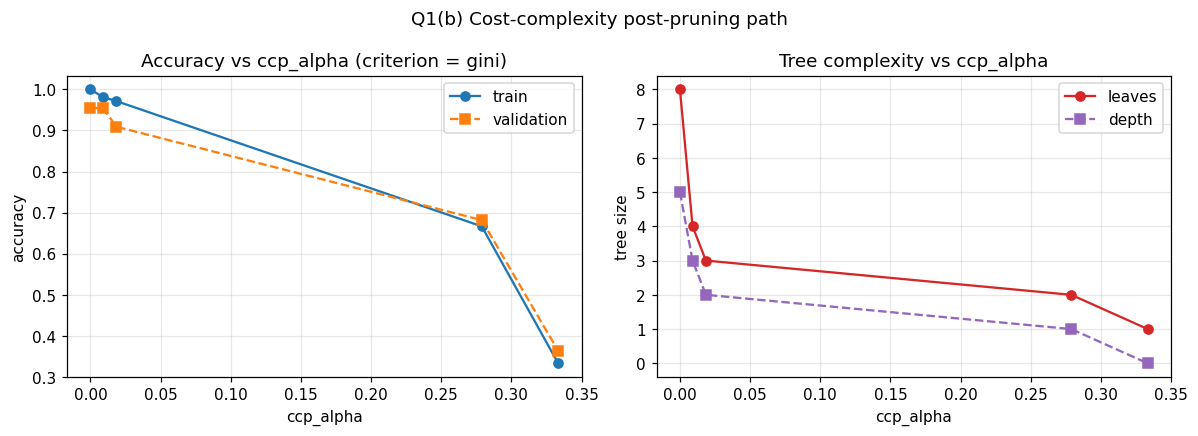

Best validation accuracy on the path : 0.9545  (2 alphas tie)
Selected ccp_alpha = 0.00899  ->  depth=3, leaves=4

                          model  train_acc  val_acc  depth  n_leaves
       pre-pruned (max_depth=3)   0.980952 0.954545      3         5
post-pruned (ccp_alpha=0.00899)   0.980952 0.954545      3         4

Identical predictions on all 150 points?  False


In [9]:
# =============================================================================
# Q1 (b) - PART 4 : ccp_alpha PLOTS AND SELECTION
# =============================================================================
# Tie-break here is the mirror image of the max_depth rule: among alphas with
# equal validation accuracy, take the LARGEST alpha, because larger alpha means
# a smaller tree and the same simplicity argument applies.
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
axes[0].plot(ccp_df.ccp_alpha, ccp_df.train_acc, "o-", label="train")
axes[0].plot(ccp_df.ccp_alpha, ccp_df.val_acc, "s--", label="validation")
axes[0].set_xlabel("ccp_alpha"); axes[0].set_ylabel("accuracy")
axes[0].set_title("Accuracy vs ccp_alpha (criterion = %s)" % best_crit)
axes[0].legend()
axes[1].plot(ccp_df.ccp_alpha, ccp_df.n_leaves, "o-", color="tab:red", label="leaves")
axes[1].plot(ccp_df.ccp_alpha, ccp_df.depth, "s--", color="tab:purple", label="depth")
axes[1].set_xlabel("ccp_alpha"); axes[1].set_ylabel("tree size")
axes[1].set_title("Tree complexity vs ccp_alpha")
axes[1].legend()
fig.suptitle("Q1(b) Cost-complexity post-pruning path")
fig.tight_layout()
fig.savefig(f"{FIGDIR}/q1_ccp.png", bbox_inches="tight")
plt.show()

best_val_ccp = ccp_df.val_acc.max()
tied = ccp_df[np.isclose(ccp_df.val_acc, best_val_ccp)]
best_alpha = float(tied.ccp_alpha.max())
post_pruned = pruned_store[best_alpha]

print("Best validation accuracy on the path : %.4f  (%d alphas tie)" %
      (best_val_ccp, len(tied)))
print("Selected ccp_alpha = %.5f  ->  depth=%d, leaves=%d" %
      (best_alpha, post_pruned.get_depth(), post_pruned.get_n_leaves()))

cmp_tbl = pd.DataFrame({
    "model": ["pre-pruned (max_depth=%s)" % best_depth_label,
              "post-pruned (ccp_alpha=%.5f)" % best_alpha],
    "train_acc": [accuracy_score(y_tr_i, pre_pruned.predict(X_tr_i)),
                  accuracy_score(y_tr_i, post_pruned.predict(X_tr_i))],
    "val_acc": [accuracy_score(y_val_i, pre_pruned.predict(X_val_i)),
                accuracy_score(y_val_i, post_pruned.predict(X_val_i))],
    "depth": [pre_pruned.get_depth(), post_pruned.get_depth()],
    "n_leaves": [pre_pruned.get_n_leaves(), post_pruned.get_n_leaves()],
})
print()
print(cmp_tbl.to_string(index=False))

# Are the two selected models actually the same function? Comparing their
# predictions on train+val+test tells us whether the comparison in part (c) is
# a comparison of two models or of two routes to one model.
allX_i = np.vstack([X_tr_i, X_val_i, X_te_i])
same_fn = bool(np.array_equal(pre_pruned.predict(allX_i), post_pruned.predict(allX_i)))
print("\nIdentical predictions on all 150 points? ", same_fn)

RESULTS["q1_post"] = {"best_alpha": best_alpha, "n_tied_alphas": int(len(tied)),
                      "post_depth": int(post_pruned.get_depth()),
                      "post_leaves": int(post_pruned.get_n_leaves()),
                      "post_val_acc": float(best_val_ccp),
                      "identical_predictions": same_fn}
RESULTS["q1_model_compare"] = cmp_tbl.to_dict(orient="records")

TEST SET (n = 23)
      model  accuracy  precision_macro  recall_macro  f1_macro
 pre-pruned    1.0000           1.0000        1.0000    1.0000
post-pruned    0.9130           0.9333        0.9167    0.9153

Per-class report, pre-pruned model:
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000         7
  versicolor     1.0000    1.0000    1.0000         8
   virginica     1.0000    1.0000    1.0000         8

    accuracy                         1.0000        23
   macro avg     1.0000    1.0000    1.0000        23
weighted avg     1.0000    1.0000    1.0000        23

Per-class report, post-pruned model:
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000         7
  versicolor     1.0000    0.7500    0.8571         8
   virginica     0.8000    1.0000    0.8889         8

    accuracy                         0.9130        23
   macro avg     0.9333    0.9167    0.9153        23
weighted avg

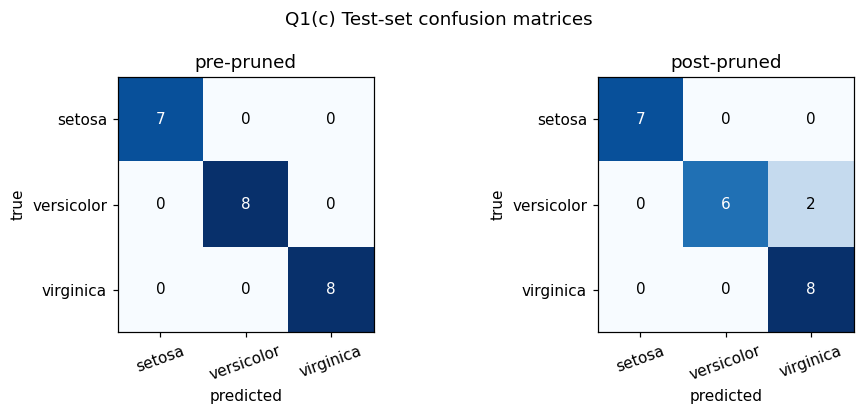

pre-pruned : 23/23 correct, Wilson 95% CI = [0.857, 1.000]
post-pruned : 21/23 correct, Wilson 95% CI = [0.732, 0.976]


In [10]:
# =============================================================================
# Q1 (c) - PART 1 : TEST-SET EVALUATION OF BOTH SELECTED MODELS
# =============================================================================
# MACRO AVERAGING. Compute precision, recall and F1 per class and then take the
# unweighted mean over classes. Macro therefore gives each class the same vote
# regardless of its support, which is the right choice when we care about the
# rare classes as much as the common ones. (Micro averaging would pool the
# counts first and, in a single-label multiclass problem where every sample gets
# exactly one predicted label, micro-P = micro-R = micro-F1 = accuracy, so it
# would add no information beyond the accuracy column.)
#
# zero_division=0 is set explicitly so that a class which is never predicted
# contributes precision 0 rather than raising a warning and silently skewing
# the macro mean.
# =============================================================================

def eval_clf(model, X, y):
    p = model.predict(X)
    return {"accuracy": accuracy_score(y, p),
            "precision_macro": precision_score(y, p, average="macro", zero_division=0),
            "recall_macro": recall_score(y, p, average="macro", zero_division=0),
            "f1_macro": f1_score(y, p, average="macro", zero_division=0)}

test_rows = []
for name, m in [("pre-pruned", pre_pruned), ("post-pruned", post_pruned)]:
    r = eval_clf(m, X_te_i, y_te_i); r["model"] = name
    test_rows.append(r)
test_df = pd.DataFrame(test_rows)[["model", "accuracy", "precision_macro",
                                   "recall_macro", "f1_macro"]]
print("TEST SET (n = %d)" % len(y_te_i))
print(test_df.to_string(index=False, float_format=lambda v: "%.4f" % v))

print("\nPer-class report, pre-pruned model:")
print(classification_report(y_te_i, pre_pruned.predict(X_te_i),
                            target_names=CLASSES_IRIS, digits=4, zero_division=0))
print("Per-class report, post-pruned model:")
print(classification_report(y_te_i, post_pruned.predict(X_te_i),
                            target_names=CLASSES_IRIS, digits=4, zero_division=0))

cm_pre = confusion_matrix(y_te_i, pre_pruned.predict(X_te_i))
cm_post = confusion_matrix(y_te_i, post_pruned.predict(X_te_i))
print("Confusion matrix (pre-pruned), rows = true, cols = predicted:")
print(pd.DataFrame(cm_pre, index=CLASSES_IRIS, columns=CLASSES_IRIS))
print("\nConfusion matrix (post-pruned):")
print(pd.DataFrame(cm_post, index=CLASSES_IRIS, columns=CLASSES_IRIS))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, cm, ttl in [(axes[0], cm_pre, "pre-pruned"), (axes[1], cm_post, "post-pruned")]:
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xticklabels(CLASSES_IRIS, rotation=20); ax.set_yticklabels(CLASSES_IRIS)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(ttl)
    ax.grid(False)
    for a in range(3):
        for b in range(3):
            ax.text(b, a, cm[a, b], ha="center", va="center",
                    color="white" if cm[a, b] > cm.max() / 2 else "black")
fig.suptitle("Q1(c) Test-set confusion matrices")
fig.tight_layout()
fig.savefig(f"{FIGDIR}/q1_confusion.png", bbox_inches="tight")
plt.show()

# HOW MUCH DOES A 23-POINT TEST SET ACTUALLY TELL US? A Wilson 95% interval for
# the accuracy makes the uncertainty explicit. Any comparison between two models
# whose intervals overlap this heavily is a comparison of noise, and the report
# says so rather than declaring a winner.
def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return max(0.0, c - h), min(1.0, c + h)

ci = {}
for name, m in [("pre-pruned", pre_pruned), ("post-pruned", post_pruned)]:
    k = int((m.predict(X_te_i) == y_te_i).sum())
    lo, hi = wilson(k, len(y_te_i))
    ci[name] = {"correct": k, "n": int(len(y_te_i)), "lo": lo, "hi": hi}
    print("%s : %d/%d correct, Wilson 95%% CI = [%.3f, %.3f]"
          % (name, k, len(y_te_i), lo, hi))
RESULTS["q1_test_ci"] = ci

RESULTS["q1_test"] = test_df.to_dict(orient="records")
RESULTS["q1_cm"] = {"pre": cm_pre.tolist(), "post": cm_post.tolist()}
RESULTS["q1_per_class"] = {
    "pre": classification_report(y_te_i, pre_pruned.predict(X_te_i),
                                 target_names=CLASSES_IRIS, output_dict=True,
                                 zero_division=0),
    "post": classification_report(y_te_i, post_pruned.predict(X_te_i),
                                  target_names=CLASSES_IRIS, output_dict=True,
                                  zero_division=0)}

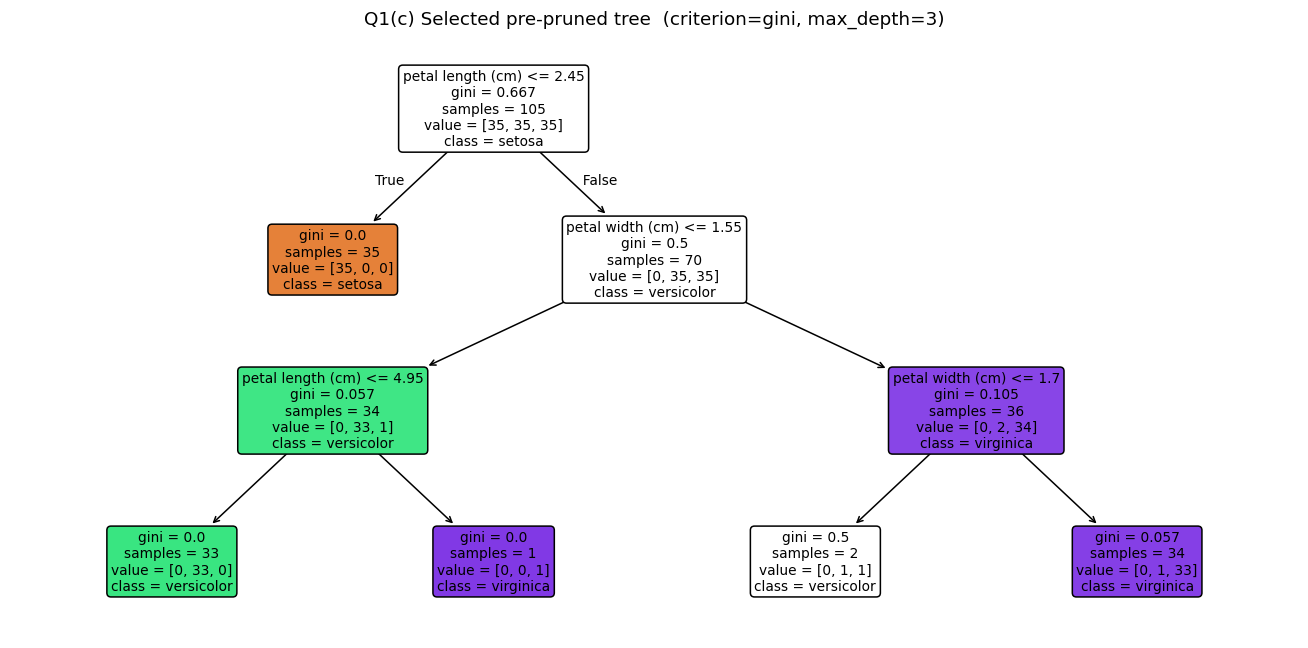

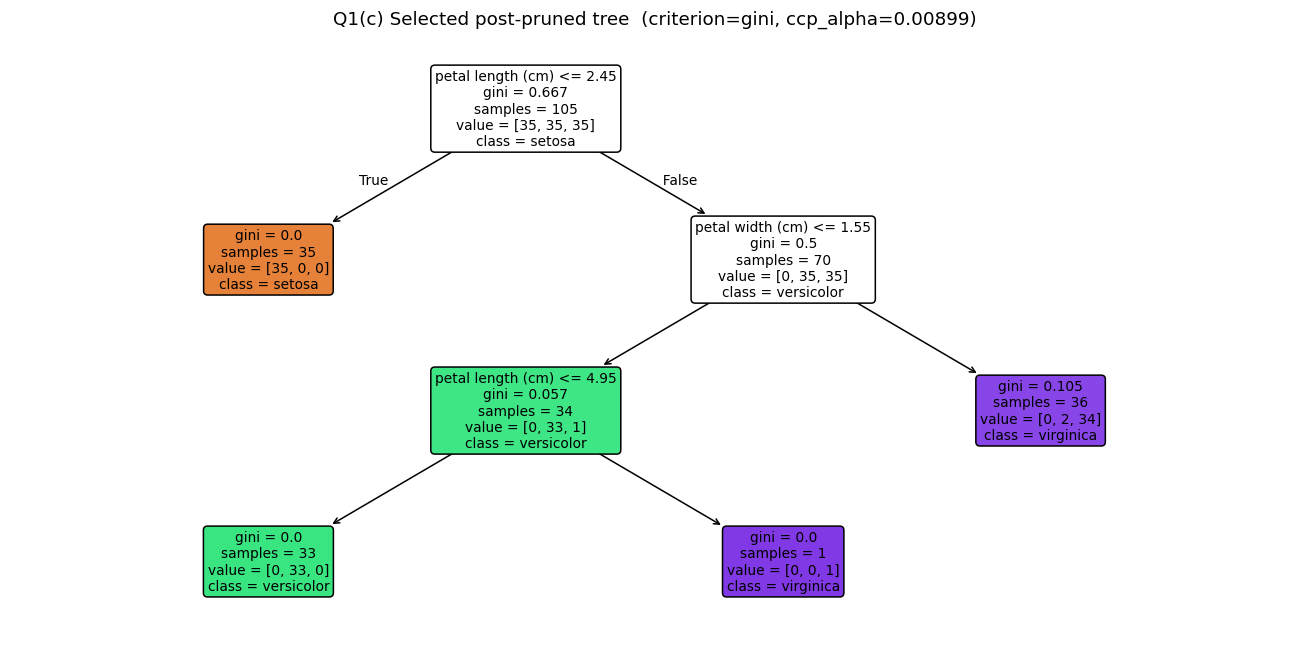

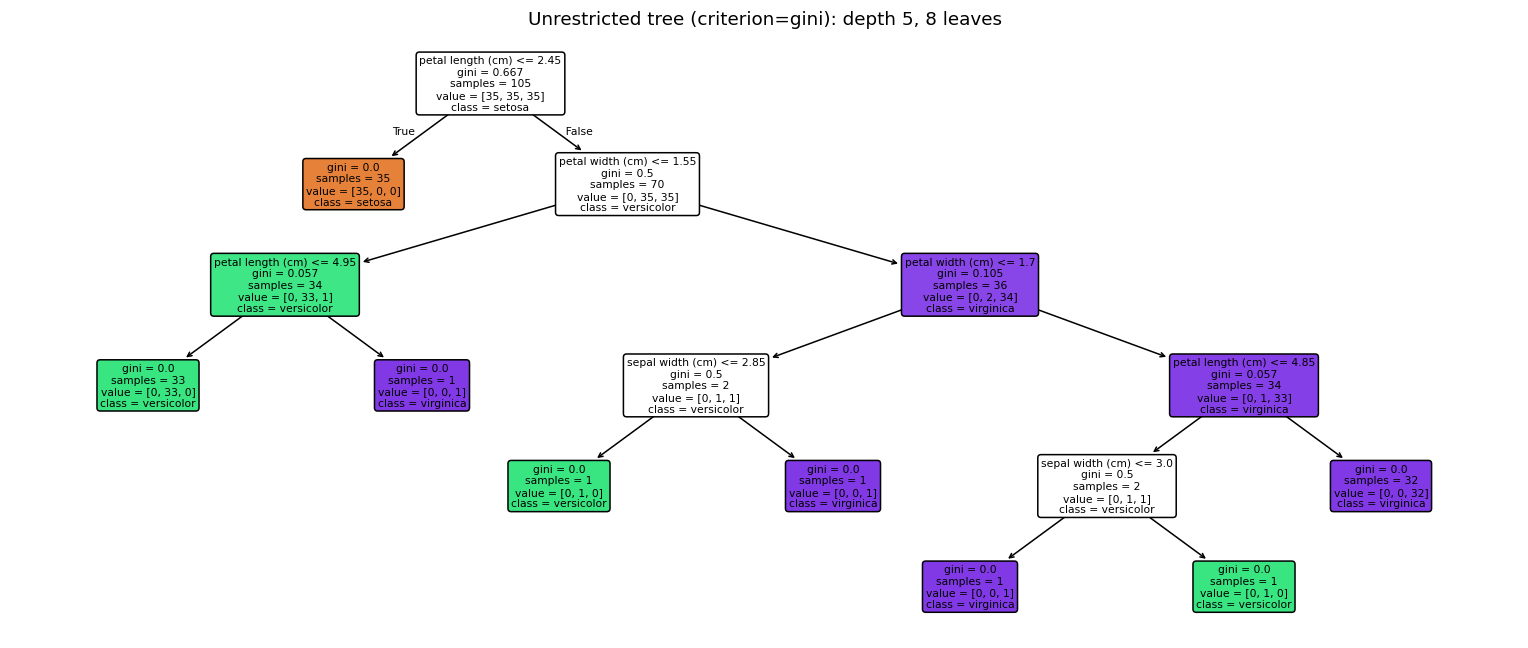

Decision rules of the selected pre-pruned tree:

|--- petal length (cm) <= 2.45
|   |--- class: setosa
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.55
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: versicolor
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: virginica
|   |--- petal width (cm) >  1.55
|   |   |--- petal width (cm) <= 1.70
|   |   |   |--- class: versicolor
|   |   |--- petal width (cm) >  1.70
|   |   |   |--- class: virginica



In [11]:
# =============================================================================
# Q1 (c) - PART 2 : TREE VISUALISATION
# =============================================================================
# Reading a node box: the first line is the split test (samples going LEFT
# satisfy it), then the impurity, then the number of training samples reaching
# the node, then the class distribution, then the majority class. Leaf colour
# saturation encodes purity.
# =============================================================================

fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(pre_pruned, feature_names=FEATS_IRIS, class_names=CLASSES_IRIS,
          filled=True, rounded=True, fontsize=9, impurity=True, ax=ax)
ax.set_title("Q1(c) Selected pre-pruned tree  (criterion=%s, max_depth=%s)"
             % (best_crit, best_depth_label))
fig.tight_layout()
fig.savefig(f"{FIGDIR}/q1_tree_pre.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(post_pruned, feature_names=FEATS_IRIS, class_names=CLASSES_IRIS,
          filled=True, rounded=True, fontsize=9, impurity=True, ax=ax)
ax.set_title("Q1(c) Selected post-pruned tree  (criterion=%s, ccp_alpha=%.5f)"
             % (best_crit, best_alpha))
fig.tight_layout()
fig.savefig(f"{FIGDIR}/q1_tree_post.png", bbox_inches="tight")
plt.show()

# The unrestricted tree, for contrast: same data, no complexity control.
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(full_tree, feature_names=FEATS_IRIS, class_names=CLASSES_IRIS,
          filled=True, rounded=True, fontsize=7, ax=ax)
ax.set_title("Unrestricted tree (criterion=%s): depth %d, %d leaves"
             % (best_crit, full_tree.get_depth(), full_tree.get_n_leaves()))
fig.tight_layout()
fig.savefig(f"{FIGDIR}/q1_tree_full.png", bbox_inches="tight")
plt.show()

print("Decision rules of the selected pre-pruned tree:\n")
print(export_text(pre_pruned, feature_names=FEATS_IRIS, class_names=CLASSES_IRIS))

RESULTS["q1_rules_pre"] = export_text(pre_pruned, feature_names=FEATS_IRIS, class_names=CLASSES_IRIS)

sepal length (cm)    0.0000
sepal width (cm)     0.0000
petal width (cm)     0.4491
petal length (cm)    0.5509
dtype: float64

corr(petal length, petal width) = 0.9629


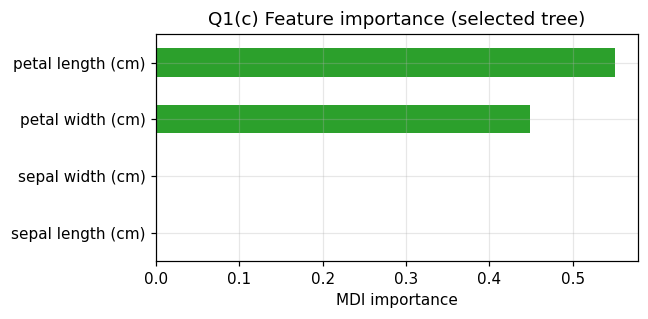

In [12]:
# =============================================================================
# Q1 (c) - PART 3 : FEATURE IMPORTANCE
# =============================================================================
# sklearn's feature_importances_ is the total weighted impurity decrease
# attributed to each feature, normalised to sum to one (MDI). Useful, but it is
# biased towards high-cardinality features and it splits credit arbitrarily
# between correlated features - petal length and petal width are correlated at
# ~0.96 on Iris, so a near-zero importance for one of them means "the other one
# was picked first", not "this feature is uninformative".
# =============================================================================

imp = pd.Series(pre_pruned.feature_importances_, index=FEATS_IRIS).sort_values()
print(imp.round(4))
corr = np.corrcoef(X_iris[:, 2], X_iris[:, 3])[0, 1]
print("\ncorr(petal length, petal width) = %.4f" % corr)

fig, ax = plt.subplots(figsize=(6, 3))
imp.plot(kind="barh", ax=ax, color="tab:green")
ax.set_xlabel("MDI importance"); ax.set_title("Q1(c) Feature importance (selected tree)")
fig.tight_layout()
fig.savefig(f"{FIGDIR}/q1_importance.png", bbox_inches="tight")
plt.show()

RESULTS["q1_importance"] = imp.to_dict()
RESULTS["q1_petal_corr"] = float(corr)

In [13]:
# =============================================================================
# Q1 - DISCUSSION (written answers required by part (c))
# =============================================================================
# 1. ENTROPY vs GINI
#    Both measure node impurity, both are zero on a pure node and maximal on the
#    uniform distribution, and both are strictly concave - the property that
#    makes the weighted impurity decrease of any split non-negative. Entropy
#    (-sum p log2 p) is the expected code length of the label; Gini (1 - sum p^2)
#    is the expected error of a randomised guesser. Numerically entropy is the
#    larger of the two on impure nodes and has a steeper gradient near purity, so
#    it is marginally more willing to spend a split isolating a small pure
#    region, while Gini leans towards the split producing the largest majority
#    class. On two classes the two disagree only in a narrow band of
#    proportions, and on this dataset they select the same structure. Cost:
#    entropy needs a logarithm per candidate split and Gini needs only products,
#    which is why Gini is scikit-learn's default.
#
# 2. WHY DEPTH CAUSES OVERFITTING
#    A tree of depth d can realise up to 2^d leaves, i.e. up to 2^d axis-aligned
#    cells, each fitted with its own constant. Capacity therefore grows
#    exponentially in depth while the sample count per leaf falls geometrically -
#    with 105 training points, a depth-7 tree has leaves holding one or two
#    samples. The class label of such a leaf is estimated from those one or two
#    points, so its variance is enormous, and the tree starts encoding the noise
#    and the accidental positions of individual training points as if they were
#    structure. Since CART grows greedily to purity, an unrestricted tree drives
#    training error to zero by construction: training accuracy of 1.0 is
#    evidence of memorisation capacity, not of quality. The signature in the
#    plots is the widening gap between a flat/declining validation curve and a
#    training curve pinned at 1.0.
#
# 3. HOW PRE- AND POST-PRUNING HELP
#    Pre-pruning (max_depth, min_samples_leaf, min_samples_split,
#    min_impurity_decrease) caps capacity before or during growth, so leaves are
#    forced to retain enough samples for their estimates to be stable. It is
#    cheap - the big tree is never built - but it is myopic: the stopping
#    decision is made without knowing what the subtree below would have achieved,
#    so a split with little immediate gain that would have unlocked two excellent
#    children is lost. Post-pruning (ccp_alpha) grows the full tree first and
#    then removes subtrees that do not justify their leaf count under
#    R_alpha(T) = R(T) + alpha|leaves(T)|, using each subtree's realised training
#    cost. It costs more compute and it can prune non-uniformly - deep where the
#    data supports depth, shallow elsewhere - which a single global depth cap
#    cannot express. Both are regularisers: they trade a little training accuracy
#    for lower variance, and the validation set decides how much of that trade is
#    worth making.
# =============================================================================
print("Q1 discussion recorded in comments above; numbers as printed in the cells.")

Q1 discussion recorded in comments above; numbers as printed in the cells.


In [14]:
# =============================================================================
# Q2 (a) - PART 1 : LOAD THE DIABETES DATA AND SPLIT 70 : 15 : 15
# =============================================================================
# 442 patients, 10 baseline features (age, sex, BMI, average blood pressure and
# six blood-serum measurements), target = a quantitative measure of disease
# progression one year after baseline. The features shipped by scikit-learn are
# already mean-centred and scaled so that each column has unit L2 norm; the
# target is NOT scaled and lives on roughly [25, 346].
#
# No stratification here - stratify= is a classification device, and the target
# is continuous. (One could stratify on binned target values; the sheet asks for
# a plain split and a plain split is what is used.)
# =============================================================================

dia = load_diabetes()
X_d, y_d = dia.data, dia.target
FEATS_D = list(dia.feature_names)

X_tr_d, X_tmp_d, y_tr_d, y_tmp_d = train_test_split(
    X_d, y_d, test_size=0.30, random_state=SEED)
X_val_d, X_te_d, y_val_d, y_te_d = train_test_split(
    X_tmp_d, y_tmp_d, test_size=0.50, random_state=SEED)

print("Feature matrix :", X_d.shape, " features:", FEATS_D)
print("Split sizes    : train=%d  val=%d  test=%d" %
      (len(y_tr_d), len(y_val_d), len(y_te_d)))

tgt_tbl = pd.DataFrame({
    "n": [len(y_tr_d), len(y_val_d), len(y_te_d)],
    "mean": [y_tr_d.mean(), y_val_d.mean(), y_te_d.mean()],
    "std": [y_tr_d.std(), y_val_d.std(), y_te_d.std()],
    "min": [y_tr_d.min(), y_val_d.min(), y_te_d.min()],
    "max": [y_tr_d.max(), y_val_d.max(), y_te_d.max()],
}, index=["train", "val", "test"]).round(3)
print()
print(tgt_tbl)

# BASELINE. The constant predictor yhat = mean(y_train) is what a depth-0 tree
# returns, so its MSE is the number every model below must beat to have earned
# its splits. Quoting MSE without this reference is meaningless.
baseline_val = mean_squared_error(y_val_d, np.full_like(y_val_d, y_tr_d.mean()))
baseline_test = mean_squared_error(y_te_d, np.full_like(y_te_d, y_tr_d.mean()))
print("\nConstant-predictor baseline : val MSE = %.2f, test MSE = %.2f"
      % (baseline_val, baseline_test))

RESULTS["q2_split"] = tgt_tbl.to_dict(orient="index")
RESULTS["q2_baseline"] = {"val_mse": float(baseline_val), "test_mse": float(baseline_test)}

Feature matrix : (442, 10)  features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Split sizes    : train=309  val=66  test=67

         n     mean     std   min    max
train  309  153.903  78.411  25.0  346.0
val     66  147.485  71.511  37.0  310.0
test    67  148.552  75.352  42.0  295.0

Constant-predictor baseline : val MSE = 5155.02, test MSE = 5706.61


In [15]:
# =============================================================================
# Q2 (a) - PART 2 : max_depth SWEEP, TRAIN AND VALIDATION MSE
# =============================================================================
# The regression tree uses the same greedy machinery as the classifier with the
# impurity replaced by the within-node variance:
#       I(node) = (1/n) sum_{i in node} (y_i - ybar_node)^2
# and the split maximising the weighted decrease
#       dI = I(parent) - (n_L/n)I(left) - (n_R/n)I(right)
# is chosen. Because the leaf constant is the node mean, dI is exactly the
# reduction in training SSE achieved by the split - "MSE reduction" and
# "variance reduction" are the same quantity here.
# =============================================================================

DEPTHS_D = [2, 3, 4, 5, 6, 8, 10, None]
rows, reg_store = [], {}
for d in DEPTHS_D:
    r = DecisionTreeRegressor(max_depth=d, random_state=SEED)
    r.fit(X_tr_d, y_tr_d)
    reg_store[("depth", "None" if d is None else d)] = r
    rows.append({"max_depth": "None" if d is None else d,
                 "train_mse": mean_squared_error(y_tr_d, r.predict(X_tr_d)),
                 "val_mse": mean_squared_error(y_val_d, r.predict(X_val_d)),
                 "realised_depth": r.get_depth(), "n_leaves": r.get_n_leaves()})
depth_d_df = pd.DataFrame(rows)
print(depth_d_df.to_string(index=False, formatters={"train_mse": "{:.2f}".format,
                                                    "val_mse": "{:.2f}".format}))
RESULTS["q2_depth_sweep"] = depth_d_df.to_dict(orient="records")

# Training MSE is monotone non-increasing in depth and reaches ~0 for the
# unrestricted tree: with continuous features and 309 distinct targets, CART can
# keep splitting until every leaf holds one sample, at which point the leaf mean
# is that sample's own target and the training residual is zero by construction.

max_depth train_mse val_mse  realised_depth  n_leaves
        2   3442.46 2955.50               2         4
        3   2918.47 3182.48               3         8
        4   2450.51 3293.51               4        16
        5   1965.72 3573.42               5        30
        6   1542.04 3939.81               6        52
        8    753.60 5337.06               8       115
       10    301.93 5319.59              10       176
     None      0.00 6207.92              17       303


In [16]:
# =============================================================================
# Q2 (b) : min_samples_leaf SWEEP AT FIXED max_depth = 10
# =============================================================================
# min_samples_leaf is a direct floor on the number of samples averaged in a
# leaf. Since the leaf prediction is a sample mean, its variance is
# sigma^2 / n_leaf, so raising the floor from 1 to m divides the leaf-level
# variance by up to m - at the cost of bias, because a leaf forced to hold m
# heterogeneous samples cannot represent a genuinely sharp local change.
# This is the bias-variance trade-off in its most literal form.
#
# Note that a candidate split is rejected outright if EITHER child would fall
# below the floor, so min_samples_leaf also shuts down growth early and the
# realised depth ends up well below the cap of 10.
# =============================================================================

MSL = [1, 2, 5, 10, 20, 50, 100]   # the last two values are there to show the U turning back up
rows = []
for m in MSL:
    r = DecisionTreeRegressor(max_depth=10, min_samples_leaf=m, random_state=SEED)
    r.fit(X_tr_d, y_tr_d)
    reg_store[("msl", m)] = r
    rows.append({"min_samples_leaf": m,
                 "train_mse": mean_squared_error(y_tr_d, r.predict(X_tr_d)),
                 "val_mse": mean_squared_error(y_val_d, r.predict(X_val_d)),
                 "realised_depth": r.get_depth(), "n_leaves": r.get_n_leaves()})
msl_df = pd.DataFrame(rows)
print(msl_df.to_string(index=False, formatters={"train_mse": "{:.2f}".format,
                                                "val_mse": "{:.2f}".format}))
RESULTS["q2_msl_sweep"] = msl_df.to_dict(orient="records")

 min_samples_leaf train_mse val_mse  realised_depth  n_leaves
                1    301.93 5319.59              10       176
                2    381.42 4901.44              10       109
                5   1173.25 4736.83              10        52
               10   2022.48 3593.29               8        23
               20   2795.71 3136.89               6        13
               50   3547.35 2940.03               3         5
              100   4312.99 3876.66               1         2


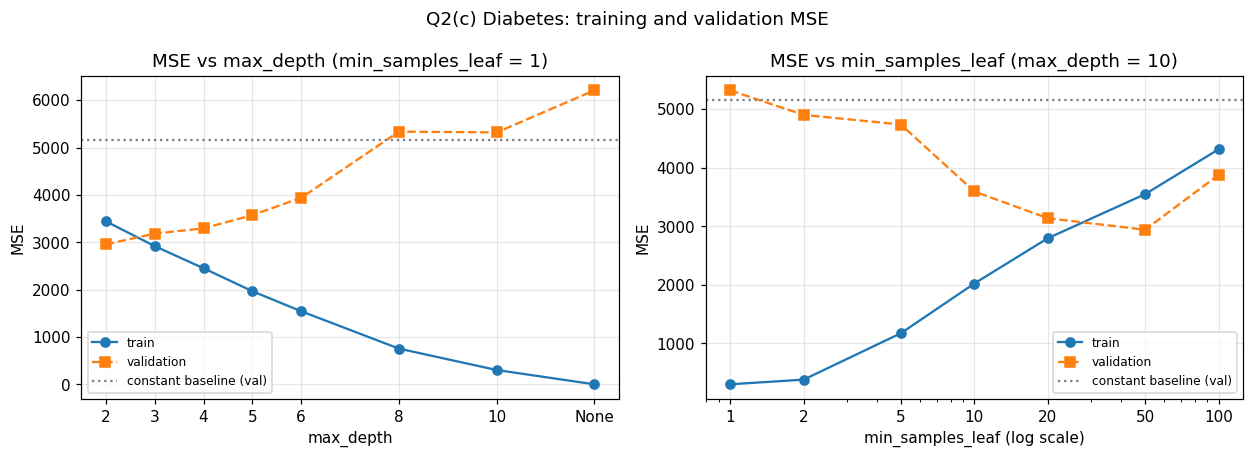

In [17]:
# =============================================================================
# Q2 (c) - PART 1 : THE TWO REQUIRED PLOTS
# =============================================================================

x_d = [d if d is not None else 12 for d in DEPTHS_D]
lbl_d = [str(d) if d is not None else "None" for d in DEPTHS_D]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
axes[0].plot(x_d, depth_d_df.train_mse, "o-", label="train")
axes[0].plot(x_d, depth_d_df.val_mse, "s--", label="validation")
axes[0].axhline(baseline_val, color="grey", ls=":", label="constant baseline (val)")
axes[0].set_xticks(x_d); axes[0].set_xticklabels(lbl_d)
axes[0].set_xlabel("max_depth"); axes[0].set_ylabel("MSE")
axes[0].set_title("MSE vs max_depth (min_samples_leaf = 1)")
axes[0].legend(fontsize=8)

axes[1].plot(msl_df.min_samples_leaf, msl_df.train_mse, "o-", label="train")
axes[1].plot(msl_df.min_samples_leaf, msl_df.val_mse, "s--", label="validation")
axes[1].axhline(baseline_val, color="grey", ls=":", label="constant baseline (val)")
axes[1].set_xscale("log"); axes[1].set_xticks(MSL)
axes[1].get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
axes[1].set_xlabel("min_samples_leaf (log scale)"); axes[1].set_ylabel("MSE")
axes[1].set_title("MSE vs min_samples_leaf (max_depth = 10)")
axes[1].legend(fontsize=8)

fig.suptitle("Q2(c) Diabetes: training and validation MSE")
fig.tight_layout()
fig.savefig(f"{FIGDIR}/q2_mse_curves.png", bbox_inches="tight")
plt.show()

Candidates ranked by validation MSE:
                            config val_mse
 max_depth=10, min_samples_leaf=50 2940.03
   max_depth=2, min_samples_leaf=1 2955.50
 max_depth=10, min_samples_leaf=20 3136.89
   max_depth=3, min_samples_leaf=1 3182.48
   max_depth=4, min_samples_leaf=1 3293.51
   max_depth=5, min_samples_leaf=1 3573.42
 max_depth=10, min_samples_leaf=10 3593.29
max_depth=10, min_samples_leaf=100 3876.66
   max_depth=6, min_samples_leaf=1 3939.81
  max_depth=10, min_samples_leaf=5 4736.83
  max_depth=10, min_samples_leaf=2 4901.44
  max_depth=10, min_samples_leaf=1 5319.59
  max_depth=10, min_samples_leaf=1 5319.59
   max_depth=8, min_samples_leaf=1 5337.06
max_depth=None, min_samples_leaf=1 6207.92

SELECTED : max_depth=10, min_samples_leaf=50   (val MSE = 2940.03)
           realised depth = 3, leaves = 5, mean samples/leaf = 61.8

Supplementary joint grid, validation MSE:
min_samples_leaf     1       2       5       10      20      50      100
max_depth              

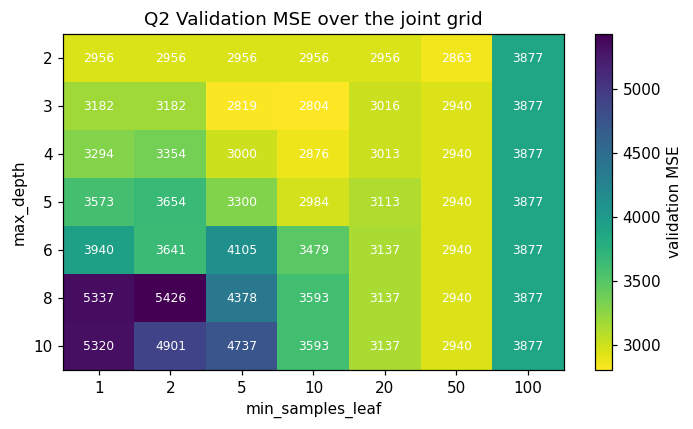

In [18]:
# =============================================================================
# Q2 (c) - PART 2 : MODEL SELECTION ON VALIDATION MSE
# =============================================================================
# The candidate set is the union of the configurations required by (a) and (b),
# and the winner is the one with the lowest validation MSE. A supplementary
# joint grid over (max_depth, min_samples_leaf) is also run below, purely to
# check whether the two one-dimensional sweeps missed an interaction; the model
# actually carried to the test set is the one selected from the required set, so
# the selection protocol stays exactly the one the sheet specifies.
# =============================================================================

cands = []
for rec in depth_d_df.to_dict("records"):
    cands.append({"config": "max_depth=%s, min_samples_leaf=1" % rec["max_depth"],
                  "key": ("depth", rec["max_depth"]), "val_mse": rec["val_mse"]})
for rec in msl_df.to_dict("records"):
    cands.append({"config": "max_depth=10, min_samples_leaf=%d" % rec["min_samples_leaf"],
                  "key": ("msl", rec["min_samples_leaf"]), "val_mse": rec["val_mse"]})
cand_df = pd.DataFrame(cands).sort_values("val_mse").reset_index(drop=True)
print("Candidates ranked by validation MSE:")
print(cand_df[["config", "val_mse"]].to_string(index=False,
                                               formatters={"val_mse": "{:.2f}".format}))

best_row = cand_df.iloc[0]
best_reg = reg_store[best_row.key]
print("\nSELECTED : %s   (val MSE = %.2f)" % (best_row.config, best_row.val_mse))
print("           realised depth = %d, leaves = %d, mean samples/leaf = %.1f"
      % (best_reg.get_depth(), best_reg.get_n_leaves(),
         len(y_tr_d) / best_reg.get_n_leaves()))

# Supplementary joint grid (analysis only, not used for the final choice).
grid_rows = []
for d in [2, 3, 4, 5, 6, 8, 10]:
    for m in MSL:
        r = DecisionTreeRegressor(max_depth=d, min_samples_leaf=m, random_state=SEED)
        r.fit(X_tr_d, y_tr_d)
        grid_rows.append({"max_depth": d, "min_samples_leaf": m,
                          "val_mse": mean_squared_error(y_val_d, r.predict(X_val_d))})
grid_df = pd.DataFrame(grid_rows)
pivot = grid_df.pivot(index="max_depth", columns="min_samples_leaf", values="val_mse")
print("\nSupplementary joint grid, validation MSE:")
print(pivot.round(1))
g_best = grid_df.loc[grid_df.val_mse.idxmin()]
print("Grid optimum : max_depth=%d, min_samples_leaf=%d, val MSE=%.2f"
      % (g_best.max_depth, g_best.min_samples_leaf, g_best.val_mse))

fig, ax = plt.subplots(figsize=(6.5, 4))
im = ax.imshow(pivot.values, cmap="viridis_r", aspect="auto")
ax.set_xticks(range(len(MSL))); ax.set_xticklabels(MSL)
ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index)
ax.set_xlabel("min_samples_leaf"); ax.set_ylabel("max_depth")
ax.set_title("Q2 Validation MSE over the joint grid"); ax.grid(False)
for a in range(pivot.shape[0]):
    for b in range(pivot.shape[1]):
        ax.text(b, a, "%.0f" % pivot.values[a, b], ha="center", va="center",
                color="w", fontsize=8)
fig.colorbar(im, ax=ax, label="validation MSE")
fig.tight_layout()
fig.savefig(f"{FIGDIR}/q2_grid.png", bbox_inches="tight")
plt.show()

RESULTS["q2_candidates"] = cand_df[["config", "val_mse"]].to_dict(orient="records")
RESULTS["q2_selected"] = {"config": best_row.config, "val_mse": float(best_row.val_mse),
                          "depth": int(best_reg.get_depth()),
                          "leaves": int(best_reg.get_n_leaves()),
                          "samples_per_leaf": float(len(y_tr_d) / best_reg.get_n_leaves())}
RESULTS["q2_grid"] = {"pivot": pivot.round(2).to_dict(),
                      "best": {"max_depth": int(g_best.max_depth),
                               "min_samples_leaf": int(g_best.min_samples_leaf),
                               "val_mse": float(g_best.val_mse)}}

Selected model (max_depth=10, min_samples_leaf=50):
            MSE    RMSE     MAE
train  3547.348  59.560  48.326
val    2940.026  54.222  41.389
test   3668.440  60.568  48.111

            model  test_MSE  test_RMSE  test_MAE
constant baseline  5706.608     75.542    66.453
unrestricted tree  5195.269     72.078    58.493
    selected tree  3668.440     60.568    48.111

Test-target std = 75.35 ; selected-model test RMSE = 60.57


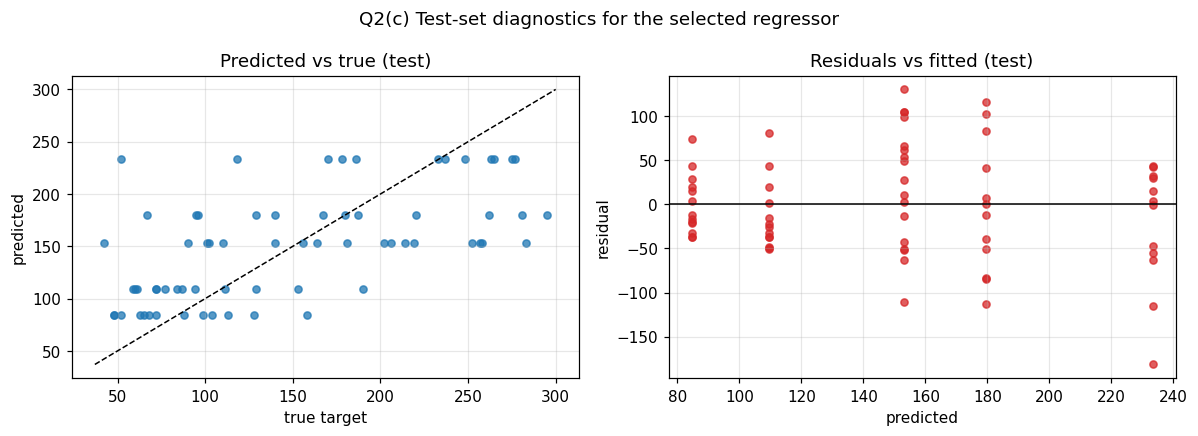

In [19]:
# =============================================================================
# Q2 (c) - PART 3 : TEST-SET EVALUATION OF THE SELECTED REGRESSOR
# =============================================================================
# MSE  : squared units of the target; dominated by the largest residuals.
# RMSE : back in the target's own units, so it is directly comparable with the
#        target standard deviation (~77 here) - that comparison is the honest
#        way to say whether the model explains anything.
# MAE  : mean absolute residual, robust to the few extreme progressions that
#        inflate MSE. RMSE > MAE always; a large ratio means a heavy residual
#        tail rather than uniformly poor fit.
# =============================================================================

def eval_reg(model, X, y):
    p = model.predict(X)
    mse = mean_squared_error(y, p)
    return {"MSE": mse, "RMSE": float(np.sqrt(mse)), "MAE": mean_absolute_error(y, p)}

sel_scores = {s: eval_reg(best_reg, X, y) for s, (X, y) in
              {"train": (X_tr_d, y_tr_d), "val": (X_val_d, y_val_d),
               "test": (X_te_d, y_te_d)}.items()}
sel_df = pd.DataFrame(sel_scores).T.round(3)
print("Selected model (%s):" % best_row.config)
print(sel_df)

unres = reg_store[("depth", "None")]
comp_rows = []
for nm, m in [("constant baseline", None), ("unrestricted tree", unres),
              ("selected tree", best_reg)]:
    if m is None:
        pred = np.full_like(y_te_d, y_tr_d.mean())
        comp_rows.append({"model": nm,
                          "test_MSE": mean_squared_error(y_te_d, pred),
                          "test_RMSE": float(np.sqrt(mean_squared_error(y_te_d, pred))),
                          "test_MAE": mean_absolute_error(y_te_d, pred)})
    else:
        s = eval_reg(m, X_te_d, y_te_d)
        comp_rows.append({"model": nm, "test_MSE": s["MSE"],
                          "test_RMSE": s["RMSE"], "test_MAE": s["MAE"]})
comp_df = pd.DataFrame(comp_rows)
print()
print(comp_df.to_string(index=False, float_format=lambda v: "%.3f" % v))

print("\nTest-target std = %.2f ; selected-model test RMSE = %.2f"
      % (y_te_d.std(), sel_scores["test"]["RMSE"]))

# Residual diagnostics: with a tree the prediction takes only n_leaves distinct
# values, so the predicted-vs-true scatter falls on horizontal bands. That
# picture is the clearest statement of what a regression tree is - a piecewise
# constant function on axis-aligned boxes.
pred_te = best_reg.predict(X_te_d)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_te_d, pred_te, s=22, alpha=0.75)
lims = [min(y_te_d.min(), pred_te.min()) - 5, max(y_te_d.max(), pred_te.max()) + 5]
axes[0].plot(lims, lims, "k--", lw=1)
axes[0].set_xlabel("true target"); axes[0].set_ylabel("predicted")
axes[0].set_title("Predicted vs true (test)")
axes[1].scatter(pred_te, y_te_d - pred_te, s=22, alpha=0.75, color="tab:red")
axes[1].axhline(0, color="k", lw=1)
axes[1].set_xlabel("predicted"); axes[1].set_ylabel("residual")
axes[1].set_title("Residuals vs fitted (test)")
fig.suptitle("Q2(c) Test-set diagnostics for the selected regressor")
fig.tight_layout()
fig.savefig(f"{FIGDIR}/q2_residuals.png", bbox_inches="tight")
plt.show()

RESULTS["q2_selected_scores"] = {k: {kk: float(vv) for kk, vv in v.items()}
                                 for k, v in sel_scores.items()}
RESULTS["q2_test_compare"] = comp_df.to_dict(orient="records")
RESULTS["q2_test_std"] = float(y_te_d.std())
RESULTS["q2_n_distinct_preds"] = int(len(np.unique(pred_te)))

In [20]:
# =============================================================================
# Q2 - VERIFYING THE TWO MECHANISMS THE SHEET ASKS US TO EXPLAIN
# =============================================================================
# Claim A : the root split is the (feature, threshold) pair maximising weighted
#           MSE reduction. Verified by brute force over every feature and every
#           midpoint between consecutive distinct values, then compared with the
#           split sklearn actually chose.
# Claim B : the prediction at a leaf is the mean of the training targets that
#           fall in it. Verified by grouping the training set with .apply() and
#           comparing group means with .predict().
# =============================================================================

def wmse(y_left, y_right):
    n = len(y_left) + len(y_right)
    def v(a):
        return 0.0 if len(a) == 0 else float(np.mean((a - a.mean()) ** 2))
    return (len(y_left) * v(y_left) + len(y_right) * v(y_right)) / n

parent_mse = float(np.mean((y_tr_d - y_tr_d.mean()) ** 2))
best = (-np.inf, None, None)
for j in range(X_tr_d.shape[1]):
    vals = np.unique(X_tr_d[:, j])
    for t in (vals[:-1] + vals[1:]) / 2.0:
        mask = X_tr_d[:, j] <= t
        if mask.sum() == 0 or (~mask).sum() == 0:
            continue
        gain = parent_mse - wmse(y_tr_d[mask], y_tr_d[~mask])
        if gain > best[0]:
            best = (gain, j, float(t))

T = unres.tree_
sk_feat = int(T.feature[0])
sk_thr = float(T.threshold[0])
# The node arrays are stored in depth-first order, so the right child of the
# root is NOT index 2 in general - it has to be read from children_right.
L, R = int(T.children_left[0]), int(T.children_right[0])
sk_gain = T.impurity[0] - (T.weighted_n_node_samples[L] * T.impurity[L] +
                           T.weighted_n_node_samples[R] * T.impurity[R]) \
                          / T.weighted_n_node_samples[0]
print("Parent (root) MSE                 : %.4f" % parent_mse)
print("Brute-force best split            : %s <= %.6f   (gain %.4f)"
      % (FEATS_D[best[1]], best[2], best[0]))
print("Split chosen by DecisionTreeRegressor : %s <= %.6f"
      % (FEATS_D[sk_feat], sk_thr))
print("Match (feature and threshold)     :", best[1] == sk_feat and abs(best[2] - sk_thr) < 1e-9)
print("Weighted impurity decrease reported by sklearn : %.4f  (brute force: %.4f)"
      % (sk_gain, best[0]))

leaf_ids = best_reg.apply(X_tr_d)
pred_tr = best_reg.predict(X_tr_d)
chk = pd.DataFrame({"leaf": leaf_ids, "y": y_tr_d, "pred": pred_tr}) \
        .groupby("leaf").agg(n=("y", "size"), leaf_mean=("y", "mean"),
                             predicted=("pred", "first"))
chk["abs_diff"] = (chk.leaf_mean - chk.predicted).abs()
print("\nLeaf-mean check over %d leaves: max |leaf mean - prediction| = %.3e"
      % (len(chk), chk.abs_diff.max()))
print(chk.head(8).round(4))

RESULTS["q2_root_split"] = {
    "parent_mse": parent_mse, "brute_feature": FEATS_D[best[1]],
    "brute_threshold": best[2], "brute_gain": float(best[0]),
    "sk_feature": FEATS_D[sk_feat], "sk_threshold": sk_thr, "sk_gain": float(sk_gain),
    "match": bool(best[1] == sk_feat and abs(best[2] - sk_thr) < 1e-9),
    "max_leaf_mean_error": float(chk.abs_diff.max()), "n_leaves_checked": int(len(chk))}

Parent (root) MSE                 : 6148.2818
Brute-force best split            : bmi <= 0.005111   (gain 1835.2874)
Split chosen by DecisionTreeRegressor : bmi <= 0.005111
Match (feature and threshold)     : True
Weighted impurity decrease reported by sklearn : 1835.2874  (brute force: 1835.2874)

Leaf-mean check over 5 leaves: max |leaf mean - prediction| = 0.000e+00
       n  leaf_mean  predicted  abs_diff
leaf                                    
3     52    84.5962    84.5962       0.0
4     64   109.4375   109.4375       0.0
5     67   153.0746   153.0746       0.0
7     65   179.4308   179.4308       0.0
8     61   233.3443   233.3443       0.0


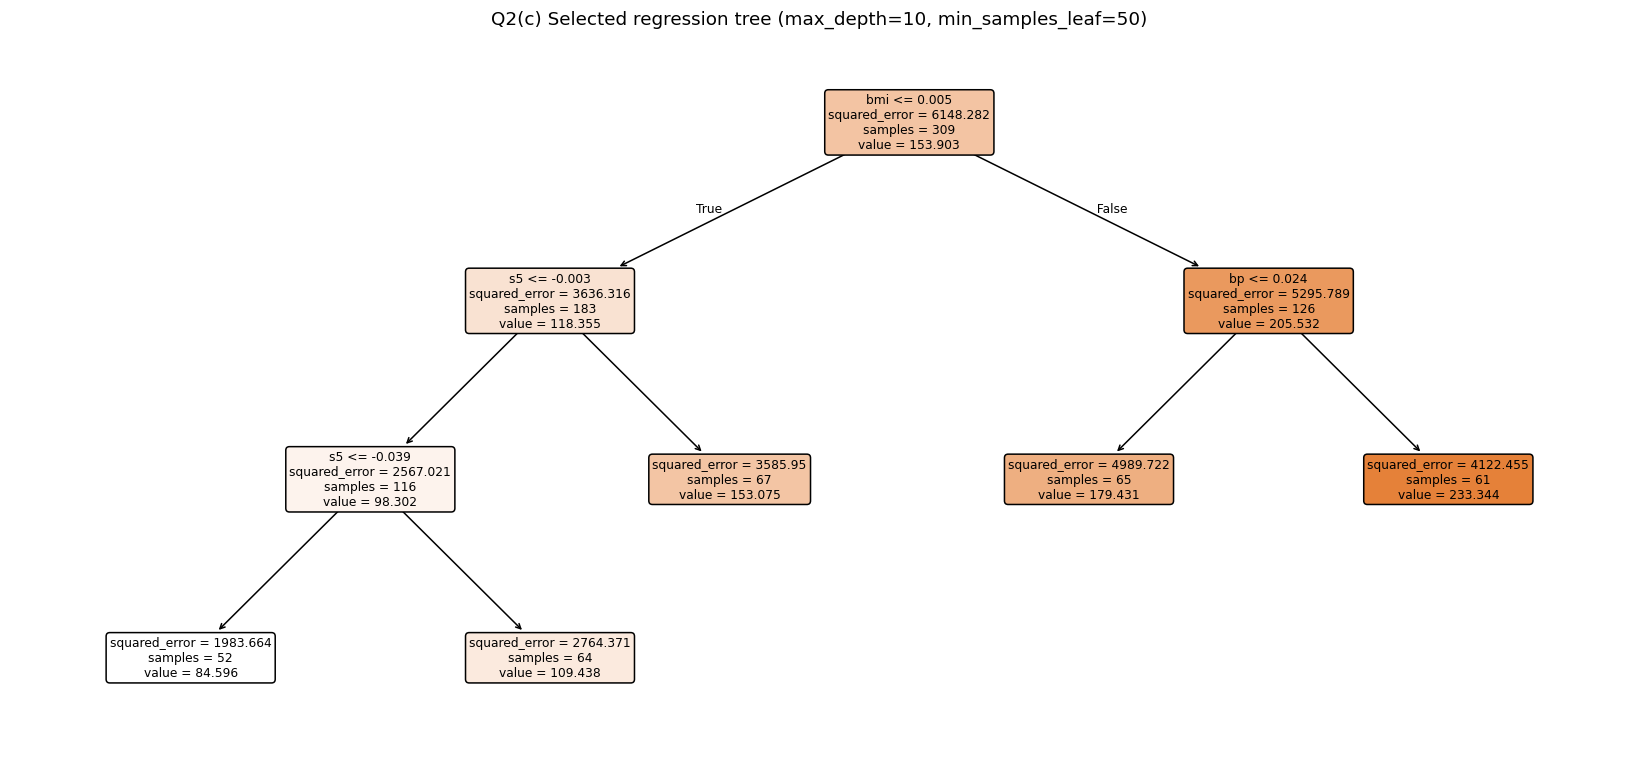

age    0.0000
sex    0.0000
s2     0.0000
s1     0.0000
s3     0.0000
s4     0.0000
s6     0.0000
bp     0.1138
s5     0.1806
bmi    0.7056
dtype: float64


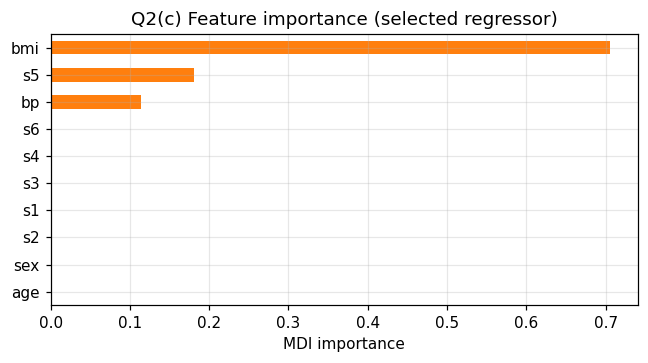


Top of the selected tree as rules:

|--- bmi <= 0.01
|   |--- s5 <= -0.00
|   |   |--- s5 <= -0.04
|   |   |   |--- value: [84.60]
|   |   |--- s5 >  -0.04
|   |   |   |--- value: [109.44]
|   |--- s5 >  -0.00
|   |   |--- value: [153.07]
|--- bmi >  0.01
|   |--- bp <= 0.02
|   |   |--- value: [179.43]
|   |--- bp >  0.02
|   |   |--- value: [233.34]



In [21]:
# =============================================================================
# Q2 (c) - PART 4 : TREE VISUALISATION AND FEATURE IMPORTANCE
# =============================================================================
# The selected tree is plotted in full if it is small enough to read, otherwise
# truncated to its top three levels (max_depth= argument of plot_tree), which is
# where the structural information lives anyway.
# =============================================================================

show_depth = None if best_reg.get_depth() <= 3 else 3
fig, ax = plt.subplots(figsize=(15, 7))
plot_tree(best_reg, feature_names=FEATS_D, filled=True, rounded=True,
          fontsize=8, max_depth=show_depth, ax=ax)
ax.set_title("Q2(c) Selected regression tree (%s)%s"
             % (best_row.config,
                "" if show_depth is None else " - top %d levels of %d"
                % (show_depth, best_reg.get_depth())))
fig.tight_layout()
fig.savefig(f"{FIGDIR}/q2_tree.png", bbox_inches="tight")
plt.show()

imp_d = pd.Series(best_reg.feature_importances_, index=FEATS_D).sort_values()
print(imp_d.round(4))
fig, ax = plt.subplots(figsize=(6, 3.4))
imp_d.plot(kind="barh", ax=ax, color="tab:orange")
ax.set_xlabel("MDI importance"); ax.set_title("Q2(c) Feature importance (selected regressor)")
fig.tight_layout()
fig.savefig(f"{FIGDIR}/q2_importance.png", bbox_inches="tight")
plt.show()

print("\nTop of the selected tree as rules:\n")
print(export_text(best_reg, feature_names=FEATS_D, max_depth=2))

RESULTS["q2_importance"] = imp_d.to_dict()
RESULTS["q2_plot_depth"] = "full" if show_depth is None else str(show_depth)

In [22]:
# =============================================================================
# Q2 - DISCUSSION (written answers required by part (c))
# =============================================================================
# 1. HOW A REGRESSION TREE PICKS A SPLIT
#    At a node containing samples S, the impurity is the within-node variance
#    I(S) = (1/|S|) sum (y_i - ybar_S)^2. For a candidate test x_j <= t giving
#    children L and R, the score is the weighted MSE reduction
#         dI = I(S) - (|L|/|S|) I(L) - (|R|/|S|) I(R),
#    and CART scans every feature and every threshold between consecutive
#    distinct feature values, keeping the maximiser. Because the leaf constant is
#    the node mean, |S| * I(S) is the node's training SSE and dI is exactly the
#    SSE the split removes; minimising total leaf SSE and maximising dI are the
#    same objective. Note dI >= 0 always - splitting can never increase training
#    error - which is precisely why an unconstrained tree runs to zero training
#    error and why an external complexity control is mandatory. The verification
#    cell above confirms this by reproducing sklearn's root split by brute force.
#
# 2. WHY THE LEAF PREDICTS THE MEAN
#    Within a leaf the model is a single constant c, fitted by minimising
#    sum_{i in leaf} (y_i - c)^2. Differentiating and setting to zero gives
#    c = ybar_leaf. So the mean is not a convention - it is the unique minimiser
#    of the squared loss the tree is built to minimise. (Under an absolute-error
#    criterion the corresponding minimiser is the median, which is what
#    criterion='absolute_error' uses.) The consequences are visible in the
#    diagnostics: predictions take only n_leaves distinct values, and the model
#    cannot extrapolate - any test point, however extreme, is mapped into some
#    leaf and receives that leaf's training mean, so predictions are confined to
#    the range of training means.
#
# 3. max_depth AND min_samples_leaf
#    max_depth caps the number of successive splits and hence the number of
#    leaves at 2^depth: it is a global cap on how finely the input space can be
#    partitioned. Small depth -> few large boxes -> high bias, low variance;
#    large depth -> many tiny boxes, each averaging almost nothing, so the leaf
#    means track the noise and variance explodes. min_samples_leaf attacks the
#    same problem from the other end by bounding the sample count in each leaf
#    from below: the variance of a leaf mean is sigma^2/n_leaf, so a floor of m
#    caps that variance at sigma^2/m regardless of where in the tree the leaf
#    sits. It is the more directly targeted control of the two, because depth is
#    only a proxy for leaf population - a depth-10 branch splitting a dense
#    region can still hold well-populated leaves, while a depth-4 branch in a
#    sparse region may not. In both sweeps the training curve improves
#    monotonically with the looser setting while validation MSE traces a U, and
#    the minimum of that U is where bias and variance balance on this dataset.
# =============================================================================
print("Q2 discussion recorded in comments above; numbers as printed in the cells.")

Q2 discussion recorded in comments above; numbers as printed in the cells.


In [23]:
# =============================================================================
# FINAL CELL : DUMP EVERY NUMBER TO results.json
# =============================================================================
# The LaTeX report is generated from this file, so no figure caption, table
# entry or inline number in the PDF is hand-transcribed.
# =============================================================================

def _clean(o):
    if isinstance(o, dict):
        return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return o

with open("results.json", "w") as f:
    json.dump(_clean(RESULTS), f, indent=2)

print("results.json written with %d top-level keys." % len(RESULTS))
print("\n================ SUMMARY ================")
print("Q1  criterion=%s, max_depth=%s -> test acc %.4f, macro F1 %.4f"
      % (best_crit, best_depth_label, RESULTS["q1_test"][0]["accuracy"],
         RESULTS["q1_test"][0]["f1_macro"]))
print("Q1  post-pruned ccp_alpha=%.5f -> test acc %.4f, macro F1 %.4f"
      % (best_alpha, RESULTS["q1_test"][1]["accuracy"],
         RESULTS["q1_test"][1]["f1_macro"]))
print("Q2  %s -> test MSE %.2f, RMSE %.2f, MAE %.2f"
      % (best_row.config, sel_scores["test"]["MSE"],
         sel_scores["test"]["RMSE"], sel_scores["test"]["MAE"]))
print("=========================================")

results.json written with 32 top-level keys.

================ SUMMARY ================
Q1  criterion=gini, max_depth=3 -> test acc 1.0000, macro F1 1.0000
Q1  post-pruned ccp_alpha=0.00899 -> test acc 0.9130, macro F1 0.9153
Q2  max_depth=10, min_samples_leaf=50 -> test MSE 3668.44, RMSE 60.57, MAE 48.11
